# BlueShift: PSA Fisheries Production Preprocessing

Prepare PSA fisheries production data for integration with BlueShift coastal ocean zones.

**Source:** PSA Fisheries: Volume of Production by Species, Geolocation, Year and Quarter  
**Unit:** Metric tons  
**Scope:** Provinces represented in the existing Mindanao coastal ocean zones

## 1. Import libraries

In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 30)

## 2. Configure project paths

In [2]:
# Run this notebook from the BlueShift project root.
PROJECT_ROOT = Path("..")

RAW_FILE = PROJECT_ROOT / "data" / "raw" / "psa" / (
    "Fisheries - Volume of Production by Species, Geolocation, Year and Quarter.csv"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "psa"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Update this path to the GeoJSON exported by the Coastal Ocean Zones notebook.
OCEAN_ZONES_FILE = (
    PROJECT_ROOT / "data" / "processed" / "ocean_zones" /
    "mindanao_coastal_ocean_zones.geojson"
)

# If the ocean-zone file uses a different province field, set it here.
OCEAN_ZONE_PROVINCE_FIELD = None

# Optional: enter the exact province names from the ocean-zone layer here.
# Leave as None to read them from OCEAN_ZONES_FILE.
COASTAL_PROVINCES = None

assert RAW_FILE.exists(), f"PSA CSV not found: {RAW_FILE}"
print("Source:", RAW_FILE)
print("Output:", PROCESSED_DIR)

Source: ..\data\raw\psa\Fisheries - Volume of Production by Species, Geolocation, Year and Quarter.csv
Output: ..\data\processed\psa


## 3. Load and inspect the PSA file

In [3]:
# The first row is the dataset title; the second row contains the headers.
raw = pd.read_csv(RAW_FILE, skiprows=1, dtype=str)

print("Shape:", raw.shape)
display(raw.head())
raw.info()

Shape: (7169, 127)


,Species,Geolocation,2002 Quarter 1,2002 Quarter 2,2002 Quarter 3,2002 Quarter 4,2002 Annual,2003 Quarter 1,2003 Quarter 2,2003 Quarter 3,2003 Quarter 4,2003 Annual,2004 Quarter 1,2004 Quarter 2,2004 Quarter 3,...,2024 Quarter 1,2024 Quarter 2,2024 Quarter 3,2024 Quarter 4,2024 Annual,2025 Quarter 1,2025 Quarter 2,2025 Quarter 3,2025 Quarter 4,2025 Annual,2026 Quarter 1,2026 Quarter 2,2026 Quarter 3,2026 Quarter 4,2026 Annual
0,ALL SPECIES,PHILIPPINES,812911.63,886413.05,774691.25,895508.07,3369524.00,816457.36,935893.60,810925.78,1056005.71,3619282.45,974016.08,991203.52,852378.25,...,990713.14,1031592.55,970098.91,1079607.60,4072012.20,1010787.47,1006478.82,902867.82,1078735.15,3998869.27,861093.46,1052242.25,886556.60,..,..
1,ALL SPECIES,..National Capital Region (NCR),40098.00,57649.00,38350.00,31946.00,168043.00,36559.00,57239.10,35512.70,29704.50,159015.30,37170.50,49432.70,33402.89,...,21115.54,48051.36,24510.69,10425.75,104103.34,21534.85,57336.00,28356.63,10740.97,117968.44,28044.72,57333.89,27063.05,..,..
2,ALL SPECIES,..Cordillera Administrative Region (CAR),1100.00,646.00,646.30,1123.70,3516.00,994.20,581.20,560.80,955.65,3091.85,941.95,567.19,523.94,...,1003.88,846.57,988.31,1178.94,4017.70,957.53,791.44,900.39,939.21,3588.57,1093.98,1246.84,752.09,..,..
3,ALL SPECIES,....Abra,113.00,92.00,82.00,93.00,380.00,112.00,94.90,85.50,74.45,366.85,122.00,101.70,86.14,...,207.35,244.82,197.34,230.43,879.94,269.19,305.44,242.14,313.00,1129.78,477.43,392.48,166.34,..,..
4,ALL SPECIES,....Apayao,54.00,32.00,43.00,57.00,186.00,40.30,36.40,52.20,55.00,183.90,44.79,37.89,31.47,...,11.44,40.26,60.24,24.81,136.75,19.35,19.39,19.78,12.54,71.06,16.41,19.24,23.89,..,..


<class 'pandas.DataFrame'>
RangeIndex: 7169 entries, 0 to 7168
Columns: 127 entries, Species to 2026 Annual
dtypes: str(127)
memory usage: 6.9 MB


## 4. Inspect columns, categories, and periods

In [4]:
print("Columns:", raw.columns.tolist()[:10], "...", raw.columns.tolist()[-5:])
print("\\nSpecies categories:", raw["Species"].nunique())
display(raw["Species"].value_counts().head(15))

print("\\nGeolocation examples:")
display(raw[["Geolocation"]].drop_duplicates().head(30))

period_columns = [
    col for col in raw.columns
    if re.fullmatch(r"\d{4} (Quarter [1-4]|Annual)", str(col))
]
print("\\nPeriod columns:", len(period_columns))
print("Years:", sorted({int(col[:4]) for col in period_columns}))

Columns: ['Species', 'Geolocation', '2002 Quarter 1', '2002 Quarter 2', '2002 Quarter 3', '2002 Quarter 4', '2002 Annual', '2003 Quarter 1', '2003 Quarter 2', '2003 Quarter 3'] ... ['2026 Quarter 1', '2026 Quarter 2', '2026 Quarter 3', '2026 Quarter 4', '2026 Annual']
\nSpecies categories: 67


Species
ALL SPECIES                          107
..Acetes (Alamang)                   107
..Anchovies (Dilis)                  107
..Big-eyed scad (Matangbaka)         107
..Bigeye tuna (Tambakol/ Bariles)    107
..Blue crab (Alimasag)               107
..Caesio (Dalagang-bukid)            107
..Cavalla (Talakitok)                107
..Crevalle (Salay-salay)             107
..Eastern little tuna (Bonito)       107
..Fimbriated sardines (Tunsoy)       107
..Flying fish (Bolador)              107
..Frigate tuna (Tulingan)            107
..Goatfish (Saramulyete)             107
..Grouper (Lapu-lapu)                107
Name: count, dtype: int64

\nGeolocation examples:


,Geolocation
0,PHILIPPINES
1,..National Capital Region (NCR)
2,..Cordillera Administrative Region (CAR)
3,....Abra
4,....Apayao
5,....Benguet
6,....Ifugao
7,....Kalinga
8,....Mountain Province
9,..Region I (Ilocos Region)


\nPeriod columns: 125
Years: [2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]


## 5. Clean column names and source values

In [5]:
df = raw.copy()
df.columns = [str(col).strip() for col in df.columns]

df["Species"] = df["Species"].astype("string").str.strip()
df["species"] = df["Species"].str.replace(r"^\.+", "", regex=True).str.strip()
df["Geolocation"] = df["Geolocation"].astype("string").str.strip()

# Keep source strings; convert only recognized numeric observations.
for col in period_columns:
    df[col] = df[col].astype("string").str.strip()

print("Rows:", len(df))
print("Duplicate full rows:", df.duplicated().sum())

Rows: 7169
Duplicate full rows: 0


## 6. Check missing values and duplicates

In [6]:
# PSA source markers: '..' = unavailable, '.' = not applicable.
source_markers = {"..", "."}

marker_counts = {}
for col in period_columns:
    marker_counts[col] = df[col].isin(source_markers).sum()

print("Unavailable (..):", sum(
    (df[col] == "..").sum() for col in period_columns
))
print("Not applicable (.):", sum(
    (df[col] == ".").sum() for col in period_columns
))

duplicate_keys = df.duplicated(subset=["Species", "Geolocation"], keep=False)
print("Repeated Species + Geolocation keys:", duplicate_keys.sum())

if duplicate_keys.any():
    display(df.loc[duplicate_keys, ["Species", "Geolocation"]].head(20))

# Do not remove duplicates automatically. Resolve only after reviewing the report.

Unavailable (..): 386707
Not applicable (.): 0
Repeated Species + Geolocation keys: 0


## 7. Standardize province names

In [7]:
def clean_geolocation(value):
    if pd.isna(value):
        return pd.NA
    # Remove the hierarchy prefix used by PSA.
    return re.sub(r"^\.+", "", str(value)).strip()

df["geolocation_label"] = df["Geolocation"].map(clean_geolocation)

# Province-level records use four leading dots in this PSA export.
df["is_province_record"] = df["Geolocation"].str.startswith("....", na=False)

# City-level records are retained in the source but are not province records.
province_rows = df.loc[df["is_province_record"]].copy()

# Explicit source-name corrections.
PROVINCE_ALIASES = {
    "tawi-tawi": "Tawi-Tawi",
    "sulu a/": "Sulu",
    "zamboanga sibugay": "Zamboanga Sibugay",
    "davao de oro": "Davao de Oro",
    "maguindanao del norte": "Maguindanao del Norte",
    "maguindanao del sur": "Maguindanao del Sur",
}

def normalize_province(value):
    if pd.isna(value):
        return pd.NA
    key = str(value).strip().casefold()
    return PROVINCE_ALIASES.get(key, str(value).strip())

province_rows["province"] = province_rows["geolocation_label"].map(
    normalize_province
)

print("Province-level rows:", len(province_rows))
print("Unique province labels:", province_rows["province"].nunique())
display(
    province_rows[["Geolocation", "geolocation_label", "province"]]
    .drop_duplicates()
    .sort_values("province")
)

Province-level rows: 5896
Unique province labels: 87


,Geolocation,geolocation_label,province
3,....Abra,Abra,Abra
94,....Agusan del Norte,Agusan del Norte,Agusan del Norte
95,....Agusan del Sur,Agusan del Sur,Agusan del Sur
49,....Aklan,Aklan,Aklan
42,....Albay,Albay,Albay
...,...,...,...
106,....Tawi-tawi,Tawi-tawi,Tawi-Tawi
27,....Zambales,Zambales,Zambales
73,....Zamboanga Sibugay,Zamboanga Sibugay,Zamboanga Sibugay
71,....Zamboanga del Norte,Zamboanga del Norte,Zamboanga del Norte


## 8. Load the BlueShift coastal province scope

In [8]:
def load_coastal_provinces():
    if COASTAL_PROVINCES is not None:
        return sorted({normalize_province(p) for p in COASTAL_PROVINCES})

    if not OCEAN_ZONES_FILE.exists():
        raise FileNotFoundError(
            "The previous ocean-zone GeoJSON was not found. Update "
            "OCEAN_ZONES_FILE or provide COASTAL_PROVINCES using the exact "
            "province list from the completed Coastal Ocean Zones notebook."
        )

    with open(OCEAN_ZONES_FILE, "r", encoding="utf-8") as f:
        geojson = json.load(f)

    features = geojson.get("features", [])
    if not features:
        raise ValueError("No features found in the ocean-zone GeoJSON.")

    property_names = list(features[0].get("properties", {}).keys())
    field = OCEAN_ZONE_PROVINCE_FIELD

    if field is None:
        candidates = ["province", "Province", "PROVINCE", "province_name"]
        field = next((name for name in candidates if name in property_names), None)

    if field is None or field not in property_names:
        raise KeyError(
            f"Could not identify province field. Available fields: {property_names}. "
            "Set OCEAN_ZONE_PROVINCE_FIELD."
        )

    names = {
        normalize_province(feature.get("properties", {}).get(field))
        for feature in features
    }
    return sorted(name for name in names if pd.notna(name))

coastal_provinces = load_coastal_provinces()

print("Coastal provinces in ocean-zone scope:", len(coastal_provinces))
display(pd.DataFrame({"province": coastal_provinces}))

Coastal provinces in ocean-zone scope: 24


,province
0,Agusan del Norte
1,Basilan
2,Camiguin
3,Davao Occidental
4,Davao Oriental
5,Davao de Oro
6,Davao del Norte
7,Davao del Sur
8,Dinagat Islands
9,Lanao del Norte


## 9. Match PSA provinces to the coastal study area

In [9]:
available_psa_provinces = set(province_rows["province"].dropna().unique())
coastal_set = set(coastal_provinces)

matched_provinces = sorted(available_psa_provinces & coastal_set)
missing_from_psa = sorted(coastal_set - available_psa_provinces)
outside_scope = sorted(available_psa_provinces - coastal_set)

print("Matched provinces:", len(matched_provinces))
print("Ocean-zone provinces missing from PSA:", missing_from_psa)
print("Other PSA provinces excluded:", len(outside_scope))

assert matched_provinces, "No coastal provinces matched. Review the name mapping."

Matched provinces: 24
Ocean-zone provinces missing from PSA: []
Other PSA provinces excluded: 63


## 10. Reshape production values to long format

In [10]:
id_columns = ["Species", "species", "Geolocation", "geolocation_label",
              "is_province_record", "province"]

long_df = province_rows.melt(
    id_vars=id_columns,
    value_vars=period_columns,
    var_name="period_label",
    value_name="production_original"
)

long_df["year"] = long_df["period_label"].str.extract(r"^(\d{4})").astype("Int64")
long_df["period"] = long_df["period_label"].str.extract(
    r"(Quarter [1-4]|Annual)$"
)
long_df["quarter"] = (
    long_df["period"].str.extract(r"Quarter ([1-4])").astype("Int64")
)

original = long_df["production_original"].astype("string").str.strip()

long_df["value_status"] = np.select(
    [
        original.eq(".."),
        original.eq("."),
        original.eq("0.00"),
        original.isna() | original.eq(""),
    ],
    [
        "unavailable",
        "not_applicable",
        "below_reporting_precision",
        "missing",
    ],
    default="reported",
)

long_df["production_mt"] = pd.to_numeric(
    original.mask(original.isin(["..", ".", ""])),
    errors="coerce"
)

print("Long-format shape:", long_df.shape)
display(long_df.head())
display(long_df["value_status"].value_counts(dropna=False))

Long-format shape: (737000, 13)


,Species,species,Geolocation,geolocation_label,is_province_record,province,period_label,production_original,year,period,quarter,value_status,production_mt
0,ALL SPECIES,ALL SPECIES,....Abra,Abra,True,Abra,2002 Quarter 1,113.00,2002,Quarter 1,1,reported,113.0
1,ALL SPECIES,ALL SPECIES,....Apayao,Apayao,True,Apayao,2002 Quarter 1,54.00,2002,Quarter 1,1,reported,54.0
2,ALL SPECIES,ALL SPECIES,....Benguet,Benguet,True,Benguet,2002 Quarter 1,61.00,2002,Quarter 1,1,reported,61.0
3,ALL SPECIES,ALL SPECIES,....Ifugao,Ifugao,True,Ifugao,2002 Quarter 1,822.00,2002,Quarter 1,1,reported,822.0
4,ALL SPECIES,ALL SPECIES,....Kalinga,Kalinga,True,Kalinga,2002 Quarter 1,44.00,2002,Quarter 1,1,reported,44.0


value_status
reported                     380809
unavailable                  355635
below_reporting_precision       556
Name: count, dtype: int64

## 11. Filter to the Mindanao coastal study area

In [11]:
mindanao = long_df.loc[
    long_df["province"].isin(coastal_provinces)
].copy()

print("Filtered records:", len(mindanao))
print("Provinces represented:", mindanao["province"].nunique())
print("Unmatched coastal provinces:", sorted(
    coastal_set - set(mindanao["province"].dropna().unique())
))

assert set(mindanao["province"].dropna().unique()).issubset(coastal_set)

Filtered records: 209375
Provinces represented: 24
Unmatched coastal provinces: []


## 12. Validate production values and source markers

In [12]:
# Check for unexpected non-numeric source values.
unexpected = long_df.loc[
    long_df["production_original"].notna()
    & long_df["production_mt"].isna()
    & ~long_df["production_original"].isin(["..", ".", ""])
]

print("Unexpected non-numeric values:", len(unexpected))
if len(unexpected):
    display(unexpected["production_original"].value_counts())

print("Negative numeric values:", (long_df["production_mt"] < 0).sum())
print("Below-precision values:", (long_df["value_status"] == "below_reporting_precision").sum())

# Keep 0.00 as a numeric source value but flag it as below reporting precision.

Unexpected non-numeric values: 0
Negative numeric values: 0
Below-precision values: 556


## 13. Prepare annual provincial production

In [13]:
# Use ALL SPECIES only to avoid adding species subtotals to the total.
annual_total = mindanao.loc[
    mindanao["Species"].str.strip().str.upper().eq("ALL SPECIES")
    & mindanao["period"].eq("Annual")
].copy()

provincial_annual = (
    annual_total
    .groupby(["province", "year"], as_index=False)
    .agg(
        production_mt=("production_mt", lambda s: s.sum(min_count=1)),
        source_rows=("production_mt", "size"),
        unavailable_count=("value_status", lambda s: (s == "unavailable").sum()),
        not_applicable_count=("value_status", lambda s: (s == "not_applicable").sum()),
        below_precision_count=("value_status", lambda s: (s == "below_reporting_precision").sum()),
    )
)

provincial_annual["unit"] = "metric tons"
display(provincial_annual.head())

,province,year,production_mt,source_rows,unavailable_count,not_applicable_count,below_precision_count,unit
0,Agusan del Norte,2002,9078.0,1,0,0,0,metric tons
1,Agusan del Norte,2003,11020.0,1,0,0,0,metric tons
2,Agusan del Norte,2004,11697.06,1,0,0,0,metric tons
3,Agusan del Norte,2005,11236.5,1,0,0,0,metric tons
4,Agusan del Norte,2006,11130.64,1,0,0,0,metric tons


## 14. Prepare quarterly production

In [14]:
quarterly_total = mindanao.loc[
    mindanao["Species"].str.strip().str.upper().eq("ALL SPECIES")
    & mindanao["period"].str.startswith("Quarter", na=False)
].copy()

quarterly_total = quarterly_total[
    ["province", "year", "quarter", "production_original",
     "production_mt", "value_status"]
].sort_values(["province", "year", "quarter"])

display(quarterly_total.head())

,province,year,quarter,production_original,production_mt,value_status
76,Agusan del Norte,2002,1,2158.00,2158.0,reported
5972,Agusan del Norte,2002,2,2652.00,2652.0,reported
11868,Agusan del Norte,2002,3,2423.00,2423.0,reported
17764,Agusan del Norte,2002,4,1845.00,1845.0,reported
29556,Agusan del Norte,2003,1,2680.00,2680.0,reported


## 15. Preserve species-level production

In [15]:
# Species-level records are kept separate from ALL SPECIES totals.
species_annual = mindanao.loc[
    ~mindanao["Species"].str.strip().str.upper().eq("ALL SPECIES")
    & mindanao["period"].eq("Annual")
].copy()

species_annual = species_annual[
    ["province", "species", "year", "production_original",
     "production_mt", "value_status"]
]

display(species_annual.head())

,province,species,year,production_original,production_mt,value_status
23728,Sulu,Acetes (Alamang),2002,..,<NA>,unavailable
23729,Zamboanga del Norte,Acetes (Alamang),2002,56.00,56.0,reported
23730,Zamboanga del Sur,Acetes (Alamang),2002,..,<NA>,unavailable
23731,Zamboanga Sibugay,Acetes (Alamang),2002,396.00,396.0,reported
23734,Camiguin,Acetes (Alamang),2002,..,<NA>,unavailable


## 16. Explore annual production trends

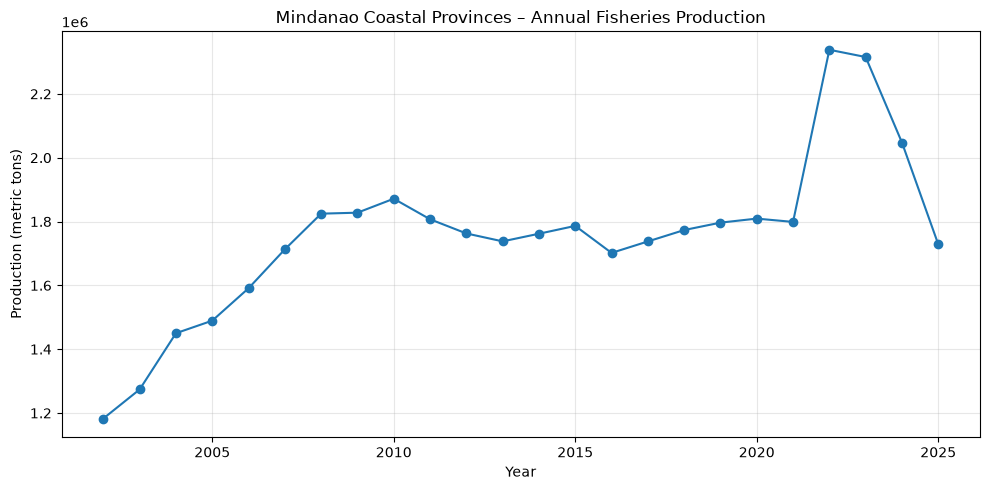

In [16]:
annual_plot = provincial_annual.dropna(subset=["production_mt"])

national_study_area = (
    annual_plot.groupby("year", as_index=False)["production_mt"]
    .sum(min_count=1)
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    national_study_area["year"],
    national_study_area["production_mt"],
    marker="o"
)
ax.set_title("Mindanao Coastal Provinces – Annual Fisheries Production")
ax.set_xlabel("Year")
ax.set_ylabel("Production (metric tons)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 17. Compare production across provinces

Latest year with annual production: 2025


,province,year,production_mt,source_rows,unavailable_count,not_applicable_count,below_precision_count,unit
523,Tawi-Tawi,2025,782913.8,1,0,0,0,metric tons
398,South Cotabato,2025,260713.67,1,0,0,0,metric tons
448,Sulu,2025,240004.94,2,1,0,0,metric tons
548,Zamboanga Sibugay,2025,73121.03,1,0,0,0,metric tons
573,Zamboanga del Norte,2025,59556.37,1,0,0,0,metric tons
248,Lanao del Norte,2025,45473.16,1,0,0,0,metric tons
298,Maguindanao del Norte,2025,34850.35,1,0,0,0,metric tons
598,Zamboanga del Sur,2025,31681.31,1,0,0,0,metric tons
48,Basilan,2025,31524.3,1,0,0,0,metric tons
123,Davao Oriental,2025,25050.8,1,0,0,0,metric tons


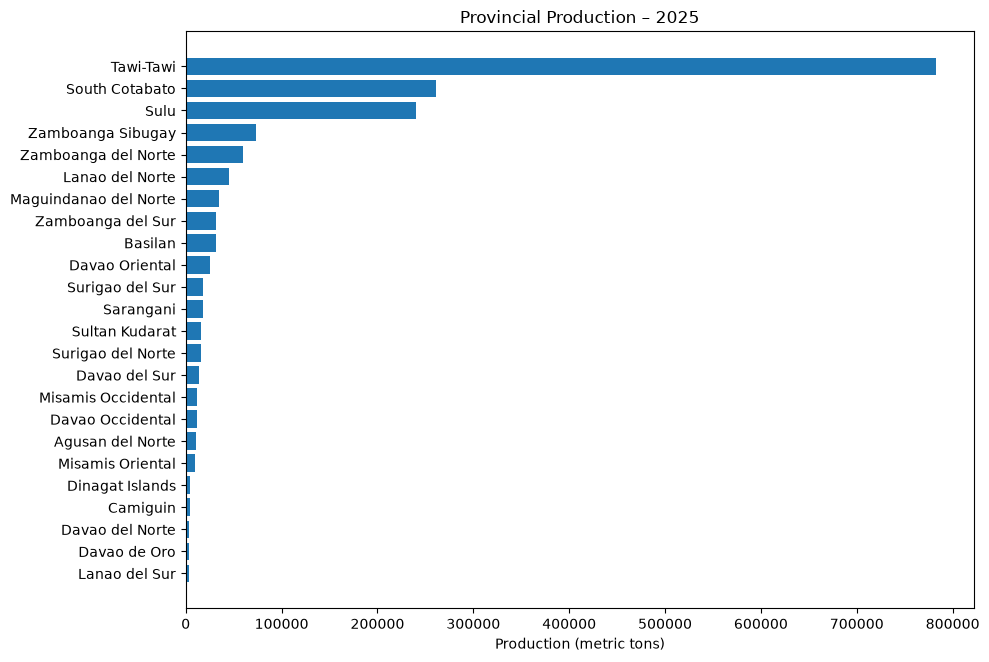

In [17]:
latest_year = provincial_annual.loc[
    provincial_annual["production_mt"].notna(), "year"
].max()
print("Latest year with annual production:", latest_year)
latest_production = provincial_annual.loc[
    provincial_annual["year"].eq(latest_year)
].dropna(subset=["production_mt"])

latest_production = latest_production.sort_values(
    "production_mt", ascending=False
)

display(latest_production)

if not latest_production.empty:
    fig, ax = plt.subplots(figsize=(10, max(5, len(latest_production) * 0.28)))
    ax.barh(
        latest_production["province"],
        latest_production["production_mt"]
    )
    ax.invert_yaxis()
    ax.set_title(f"Provincial Production – {latest_year}")
    ax.set_xlabel("Production (metric tons)")
    plt.tight_layout()
    plt.show()

## 18. Inspect species patterns

,production_mt
species,
Seaweed,972263.96
Skipjack (Gulyasan),218573.06
Yellowfin tuna (Tambakol/Bariles),58204.44
Others (Marine Fisheries),49468.71
Roundscad (Galunggong),46855.1
Big-eyed scad (Matangbaka),43747.49
Tilapia,31412.67
Bali sardinella (Tamban),31300.89
Milkfish,30774.25


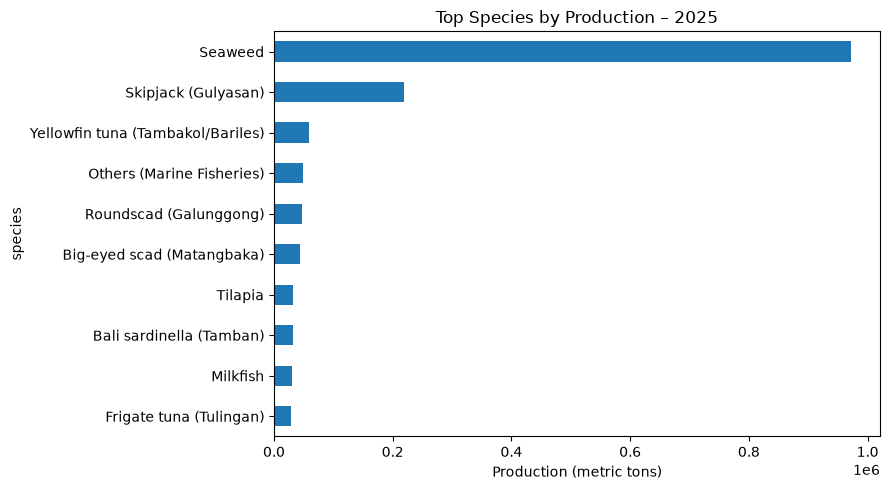

In [18]:
top_species = (
    species_annual.loc[species_annual["year"].eq(latest_year)]
    .groupby("species")["production_mt"]
    .sum(min_count=1)
    .sort_values(ascending=False)
    .head(10)
)

display(top_species.rename("production_mt").to_frame())

if not top_species.empty:
    top_species.sort_values().plot(
        kind="barh",
        figsize=(9, 5),
        title=f"Top Species by Production – {latest_year}"
    )
    plt.xlabel("Production (metric tons)")
    plt.tight_layout()
    plt.show()

## 19. Export processed datasets

In [19]:
# Preserve the full provincial long-format dataset and filtered study-area data.
cleaned_path = PROCESSED_DIR / "psa_fisheries_cleaned.csv"
mindanao_path = PROCESSED_DIR / "psa_mindanao_production.csv"
annual_path = PROCESSED_DIR / "psa_provincial_annual_production.csv"
quarterly_path = PROCESSED_DIR / "psa_provincial_quarterly_production.csv"
species_path = PROCESSED_DIR / "psa_species_annual_production.csv"

long_df.to_csv(cleaned_path, index=False)
mindanao.to_csv(mindanao_path, index=False)
provincial_annual.to_csv(annual_path, index=False)
quarterly_total.to_csv(quarterly_path, index=False)
species_annual.to_csv(species_path, index=False)

for path in [
    cleaned_path, mindanao_path, annual_path, quarterly_path, species_path
]:
    print(path.name, "-", path.stat().st_size, "bytes")

psa_fisheries_cleaned.csv - 98318426 bytes
psa_mindanao_production.csv - 29851096 bytes
psa_provincial_annual_production.csv - 29560 bytes
psa_provincial_quarterly_production.csv - 117746 bytes
psa_species_annual_production.csv - 2418846 bytes


## 20. Final validation and summary

In [20]:
print("Source rows:", len(raw))
print("Province-level source rows:", len(province_rows))
print("Mindanao coastal long records:", len(mindanao))
print("Matched coastal provinces:", mindanao["province"].nunique())
print("Annual provincial rows:", len(provincial_annual))
print("Quarterly total rows:", len(quarterly_total))
print("Species annual rows:", len(species_annual))

print("\\nYears available:", sorted(mindanao["year"].dropna().unique().tolist()))
print("\\nValue status:")
display(mindanao["value_status"].value_counts(dropna=False))

assert mindanao["province"].notna().all()
assert mindanao["year"].notna().all()
assert set(mindanao["province"].unique()).issubset(coastal_set)

print("\\nPreprocessing complete.")

Source rows: 7169
Province-level source rows: 5896
Mindanao coastal long records: 209375
Matched coastal provinces: 24
Annual provincial rows: 600
Quarterly total rows: 2500
Species annual rows: 41250
\nYears available: [2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
\nValue status:


value_status
reported                     118599
unavailable                   90534
below_reporting_precision       242
Name: count, dtype: int64

\nPreprocessing complete.
